## Figure 7

In [6]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = '.'  # /DTLC/SEI_models/hist
labels = ['a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6']
titles = ['Hydroxyl', 'Amino', 'Nitrile',
          'Carboxyl', 'Aldehyde', 'Nitro',
          'Benzene', 'Methyl', 'Butyl',
          'Cyclohexane', 'Ethyl', 'Isopropyl']
ratios = {'10:1': 'blue', '4:1': 'green', '1:1': 'red'}

#
files = {}
for label in labels:
    matches = glob.glob(os.path.join(data_dir, f'{label}_*.csv'))
    files[label] = matches[0]
files

{'a1': './a1_hist_data_CO.csv',
 'a2': './a2_hist_data_N.csv',
 'a3': './a3_hist_data_C#N.csv',
 'a4': './a4_hist_data_C(=O)O.csv',
 'a5': './a5_hist_data_C=O.csv',
 'a6': './a6_hist_data_[N+](=O)[O-].csv',
 'b1': './b1_hist_data_c1ccccc1.csv',
 'b2': './b2_hist_data_C.csv',
 'b3': './b3_hist_data_CCCC.csv',
 'b4': './b4_hist_data_C1CCCCC1.csv',
 'b5': './b5_hist_data_CC.csv',
 'b6': './b6_hist_data_C(C)C.csv'}

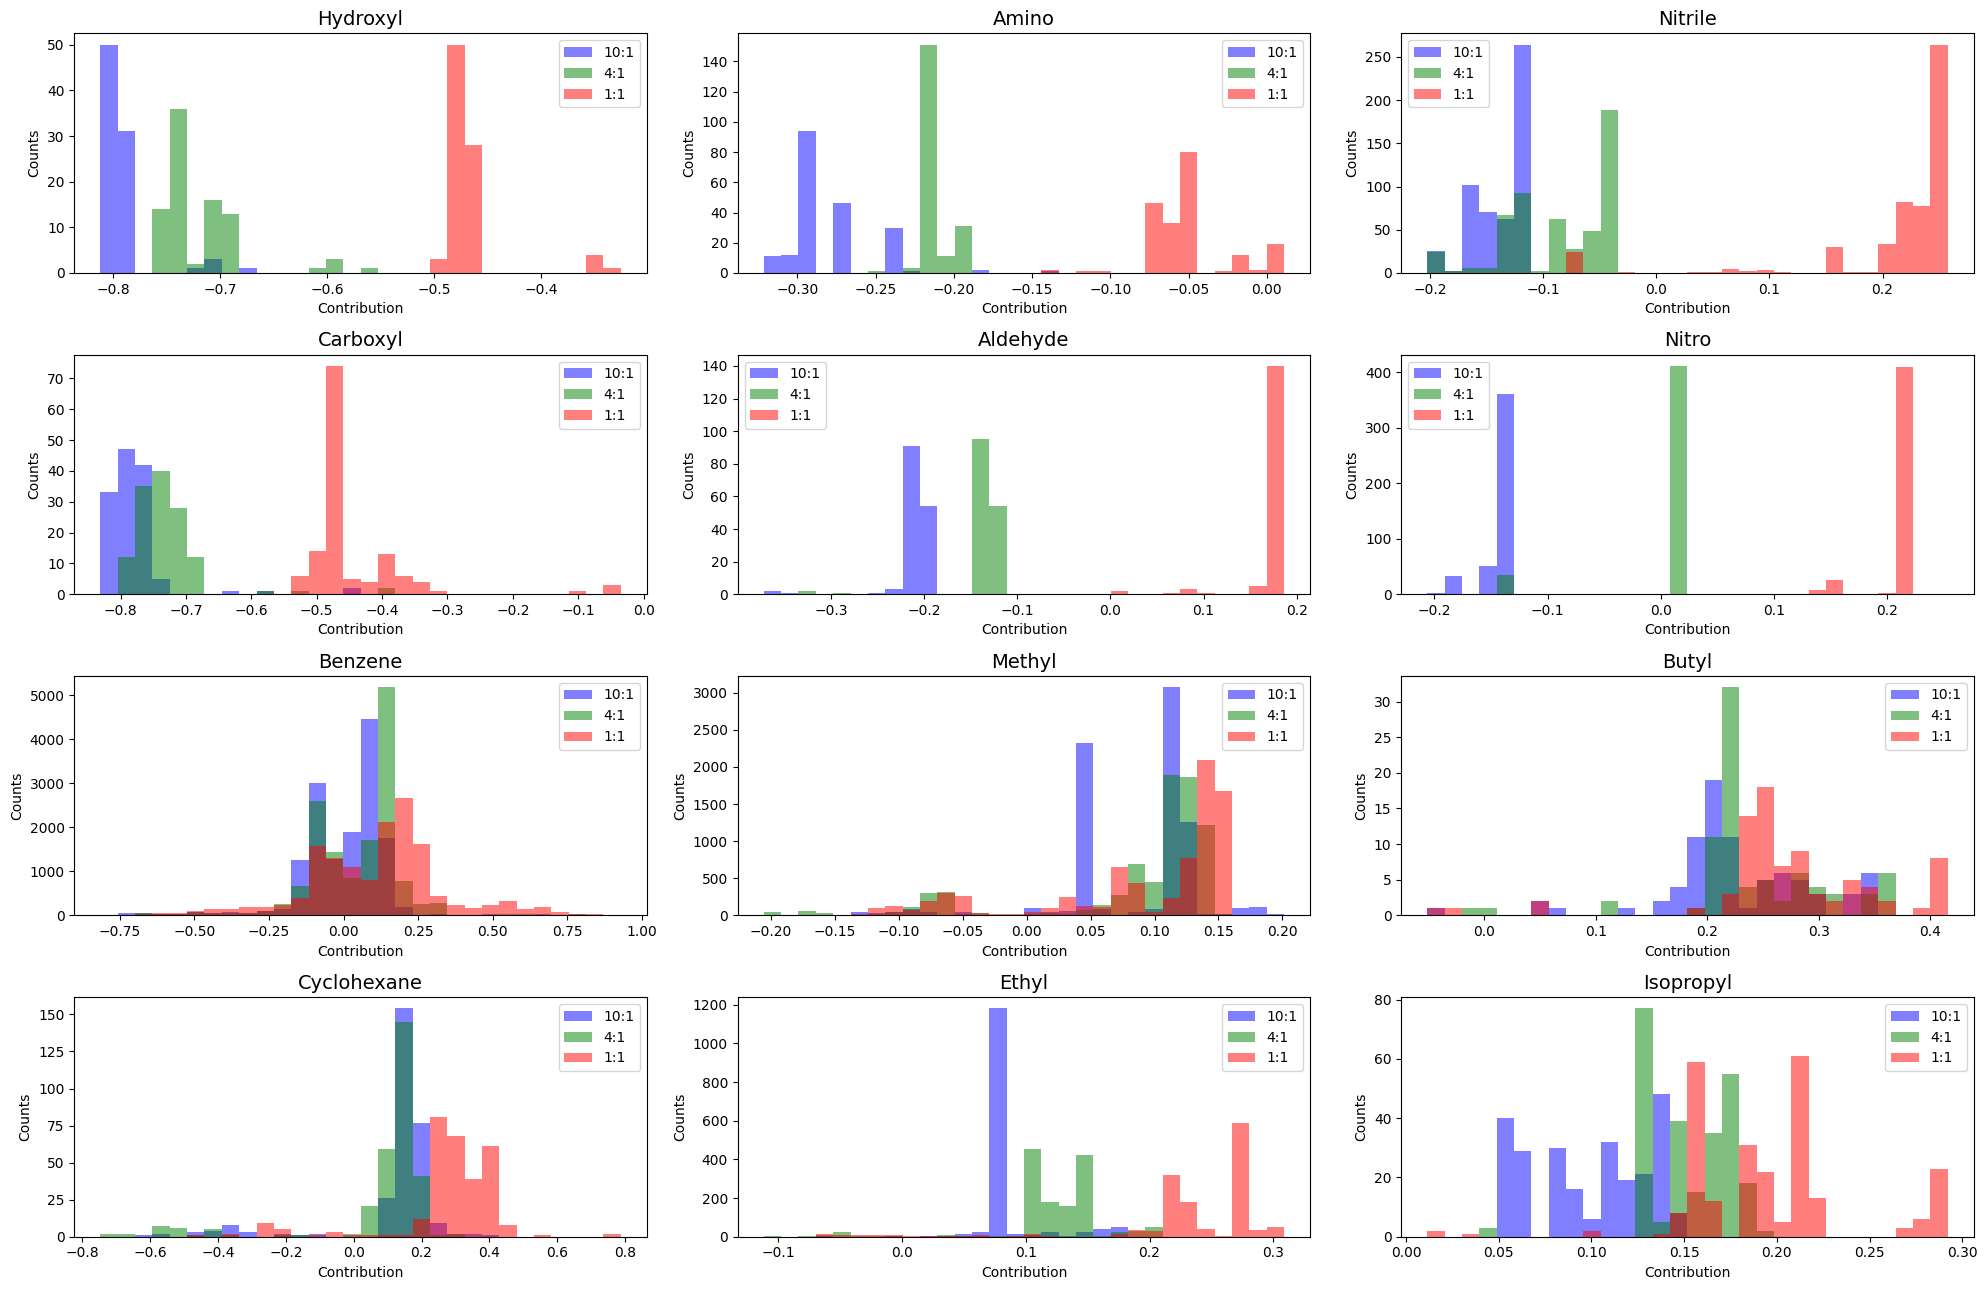

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(20, 13))

for ax, label, title in zip(axes.flat, labels, titles):
    df = pd.read_csv(files[label], header=1)
    values = [df[col].dropna().values for col in ratios]

    bins = np.histogram_bin_edges(np.concatenate(values), bins=30)
    for col, v in zip(ratios, values):
        ax.hist(v, bins=bins, color=ratios[col], alpha=0.5, label=col)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Contribution')
    ax.set_ylabel('Counts')
    ax.legend()

plt.tight_layout()
plt.show()